In [1]:
# Session 9.9 — Advanced Charts in Matplotlib
# આજે આપણે Matplotlib ના ચાર મહત્વપૂર્ણ advanced charts શીખીશું:
# 1. Stacked Bar Chart — કુલ Sales માં દરેક category નો ફાળો.
# 2. Area Chart — સમય પ્રમાણે values અને તેમના cumulative contribution નું visualization.
# 3. Error Bars — data માં variability અથવા uncertainty દર્શાવવી.
# 4. Time Series Chart — તારીખ પ્રમાણે Sales, Revenue અથવા અન્ય measurements દર્શાવવાં.
# આ charts Data Science, Business Analytics અને reporting માં ખૂબ ઉપયોગી છે.
# 1. Learning Objectives
# આ Session પૂર્ણ થયા પછી તમે:
# - bottom વડે Stacked Bar Chart બનાવી શકશો.
# - plt.stackplot() વડે Area Chart બનાવી શકશો.
# - plt.errorbar() વડે Error Bars ઉમેરશો.
# - Pandas માં dates ને datetime માં ફેરવીને Time Series Chart બનાવશો.
# - Chart માંથી યોગ્ય business insights કાઢી શકશો.



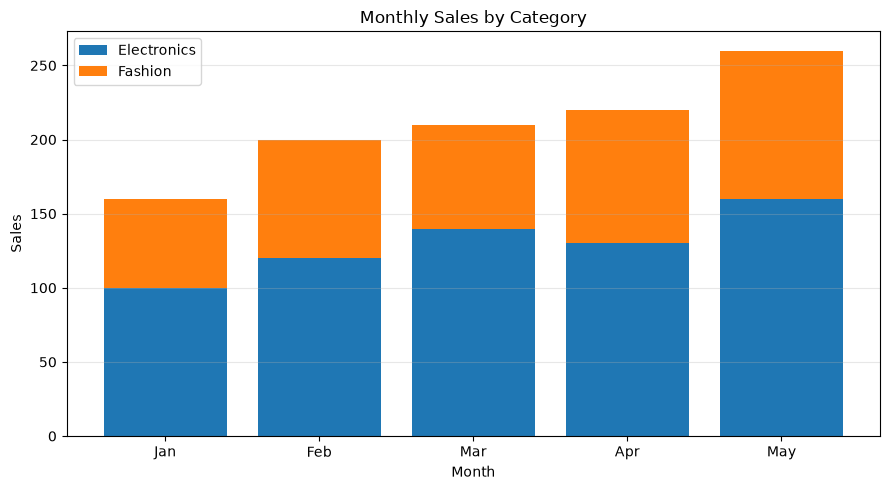

In [ ]:
# 2. Stacked Bar Chart
# Stacked Bar Chart માં એક bar ને ઘણા ભાગોમાં વહેંચવામાં આવે છે, જેથી કુલ value સાથે દરેક ભાગનું contribution પણ જોઈ શકાય.

# ઉદાહરણ: એક દુકાનના દરેક મહિના દરમિયાન Electronics અને Fashion ની Sales.
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May"]
electronics = [100, 120, 140, 130, 160]
fashion = [60, 80, 70, 90, 100]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(months, electronics, label="Electronics")
ax.bar(
    months,
    fashion,
    bottom=electronics,
    label="Fashion"
)

ax.set_title("Monthly Sales by Category")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()


# bottom=electronics શા માટે?
# સામાન્ય Bar Chart માં બંને bars એક જ baseline પરથી શરૂ થાય છે. અહીં bottom=electronics Fashion ની bar ને Electronics ની bar ની ઉપરથી શરૂ કરે છે.

# ઉદાહરણ તરીકે, January માં:
# - Electronics = 100
# - Fashion = 60
# - Total Sales = 160

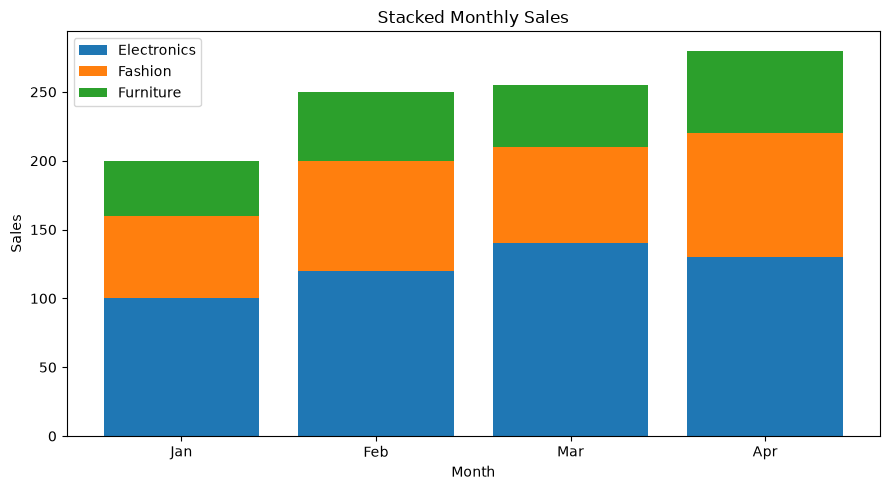

In [3]:
# ત્રણ categories સાથે Stacked Bar Chart

import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr"]

electronics = [100, 120, 140, 130]
fashion = [60, 80, 70, 90]
furniture = [40, 50, 45, 60]

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(months, electronics, label="Electronics")
ax.bar(
    months, fashion,
    bottom=electronics,
    label="Fashion"
)

bottom_two = [
    e + f for e, f in zip(electronics, fashion)
]

ax.bar(
    months, furniture,
    bottom=bottom_two,
    label="Furniture"
)

ax.set_title("Stacked Monthly Sales")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.legend()

plt.tight_layout()
plt.show()

In [4]:
# bottom_two દરેક મહિના માટે Electronics + Fashion નો સરવાળો કરે છે, જેથી Furniture યોગ્ય રીતે ઉપર દેખાય છે.

# ક્યારે વાપરવો? જ્યારે તમને total અને તેના components બંને બતાવવા હોય. જો અલગ categories ની સરખામણી મુશ્કેલ બને, તો સામાન્ય grouped Bar Chart વધુ યોગ્ય હોઈ શકે છે.


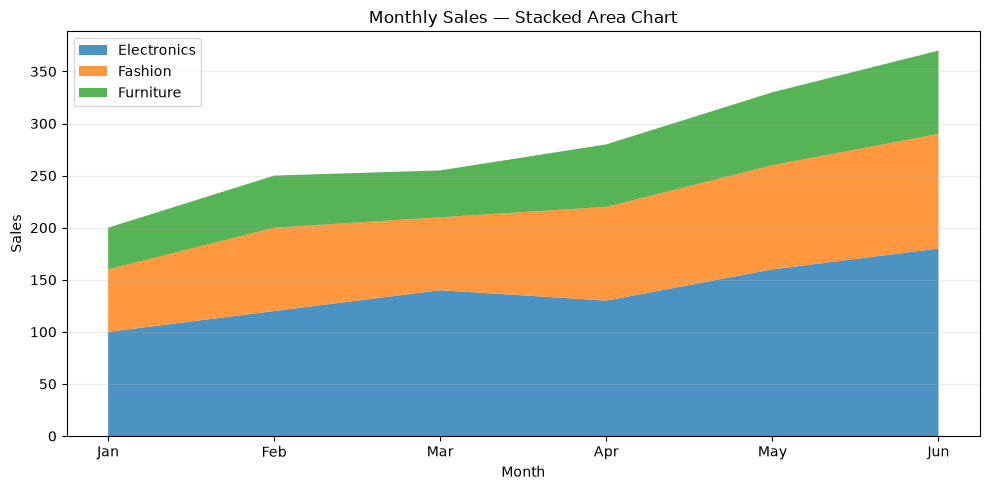

In [ ]:
# 3. Area Chart — plt.stackplot()
# Area Chart સમય પ્રમાણે values કેવી રીતે બદલાય છે તે દર્શાવે છે. Stacked Area Chart માં એકથી વધુ categories નો કુલ trend અને તેમનો ફાળો બંને જોઈ શકાય છે.

import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]

electronics = [100, 120, 140, 130, 160, 180]
fashion = [60, 80, 70, 90, 100, 110]
furniture = [40, 50, 45, 60, 70, 80]

fig, ax = plt.subplots(figsize=(10, 5))

ax.stackplot(
    months,
    electronics,
    fashion,
    furniture,
    labels=["Electronics", "Fashion", "Furniture"],
    alpha=0.8
)

ax.set_title("Monthly Sales — Stacked Area Chart")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")
ax.legend(loc="upper left")

ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


# Code સમજીએ
# Code	અર્થ
# ax.stackplot()	Stacked Area Chart બનાવે છે
# labels	દરેક area નું નામ આપે છે
# alpha=0.8	Areas માં transparency ઉમેરે છે
# ax.legend()	Categories ના નામ દર્શાવે છે

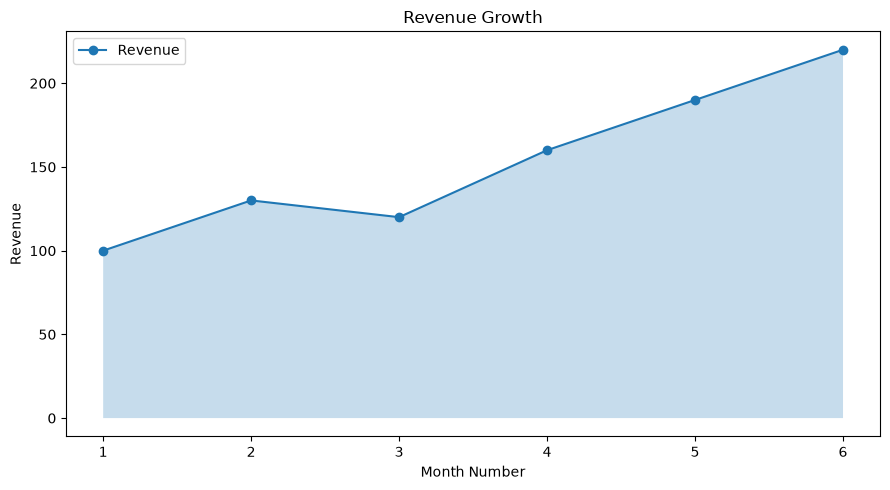

In [ ]:
# Simple Area Chart
# જો એક જ variable બતાવવો હોય, તો fill_between() ઉપયોગી છે.

import matplotlib.pyplot as plt

months = [1, 2, 3, 4, 5, 6]
revenue = [100, 130, 120, 160, 190, 220]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(months, revenue, marker="o", label="Revenue")
ax.fill_between(months, revenue, alpha=0.25)

ax.set_title("Revenue Growth")
ax.set_xlabel("Month Number")
ax.set_ylabel("Revenue")
ax.legend()

plt.tight_layout()
plt.show()
# fill_between() Line અને baseline વચ્ચેનો વિસ્તાર fill કરે છે.

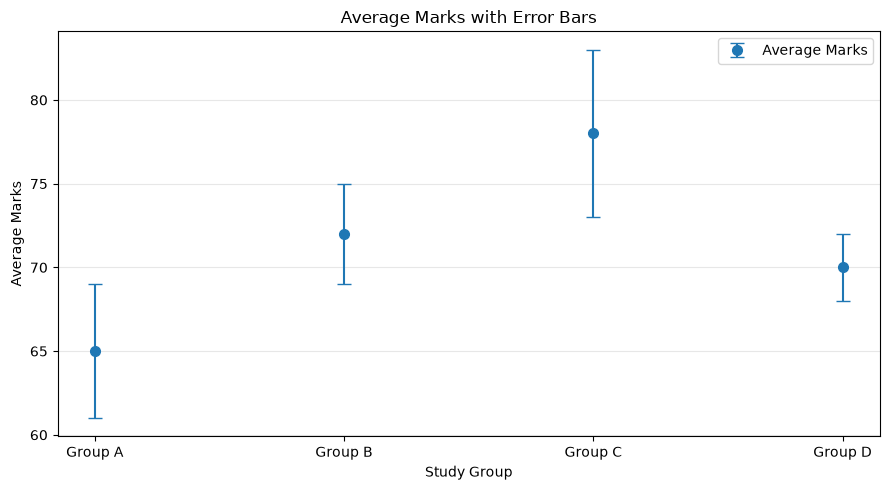

In [ ]:
# 4. Error Bars — plt.errorbar()
# કેટલીક વખત data માં એક જ value પૂરતી માહિતી આપતી નથી. Measurements માં variability અથવા uncertainty પણ હોઈ શકે છે.

# ઉદાહરણ તરીકે, અલગ study groups ના average marks સાથે દરેક group માટે uncertainty range દર્શાવવી.

import matplotlib.pyplot as plt

groups = ["Group A", "Group B", "Group C", "Group D"]
average_marks = [65, 72, 78, 70]
errors = [4, 3, 5, 2]

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    groups,
    average_marks,
    yerr=errors,
    fmt="o",
    capsize=5,
    markersize=7,
    linewidth=1.5,
    label="Average Marks"
)

ax.set_title("Average Marks with Error Bars")
ax.set_xlabel("Study Group")
ax.set_ylabel("Average Marks")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Error Bar ના parameters
# Parameter	અર્થ
# yerr	Y-direction માં uncertainty અથવા error ની માત્રા
# xerr	X-direction માં uncertainty
# fmt="o"	Data point માટે circle marker
# capsize=5	Error Bar ના છેડે cap ની લંબાઈ
# markersize=7	Marker નું કદ

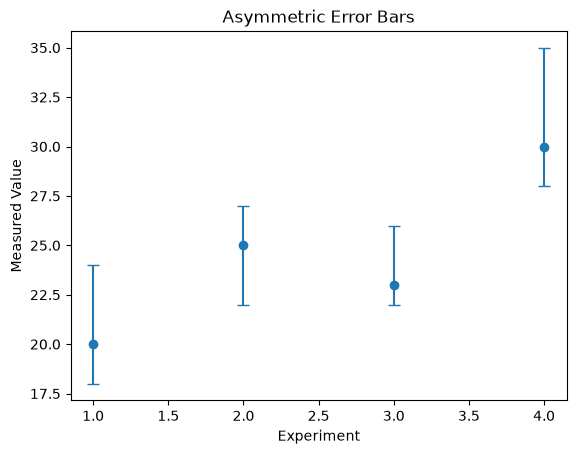

In [8]:
# Asymmetric Error Bars
# જો upper અને lower errors અલગ હોય તો:

import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [20, 25, 23, 30]

# First row = lower errors, second row = upper errors
errors = [
    [2, 3, 1, 2],
    [4, 2, 3, 5]
]

plt.errorbar(
    x, y,
    yerr=errors,
    fmt="o",
    capsize=4
)

plt.title("Asymmetric Error Bars")
plt.xlabel("Experiment")
plt.ylabel("Measured Value")
plt.show()

In [9]:
# 5. Time Series Chart — તારીખ પ્રમાણે Data
# Time Series એટલે સમયના ક્રમમાં નોંધાયેલું data. જેમ કે:
# - દરરોજની Sales
# - મહિના પ્રમાણે Revenue
# - દૈનિક Temperature
# - Website પર દર કલાકે આવતા visitors
# આવા data માટે X-axis પર તારીખ અને Y-axis પર numerical value દર્શાવવામાં આવે છે.

# Step 1 — Dates સાથે Data બનાવો

import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Date": [
        "2026-10-01",
        "2026-10-02",
        "2026-10-03",
        "2026-10-04",
        "2026-10-05",
        "2026-10-06",
        "2026-10-07"
    ],
    "Sales": [120, 135, 128, 160, 175, 165, 200]
})

df["Date"] = pd.to_datetime(df["Date"])

print(df)

        Date  Sales
0 2026-10-01    120
1 2026-10-02    135
2 2026-10-03    128
3 2026-10-04    160
4 2026-10-05    175
5 2026-10-06    165
6 2026-10-07    200


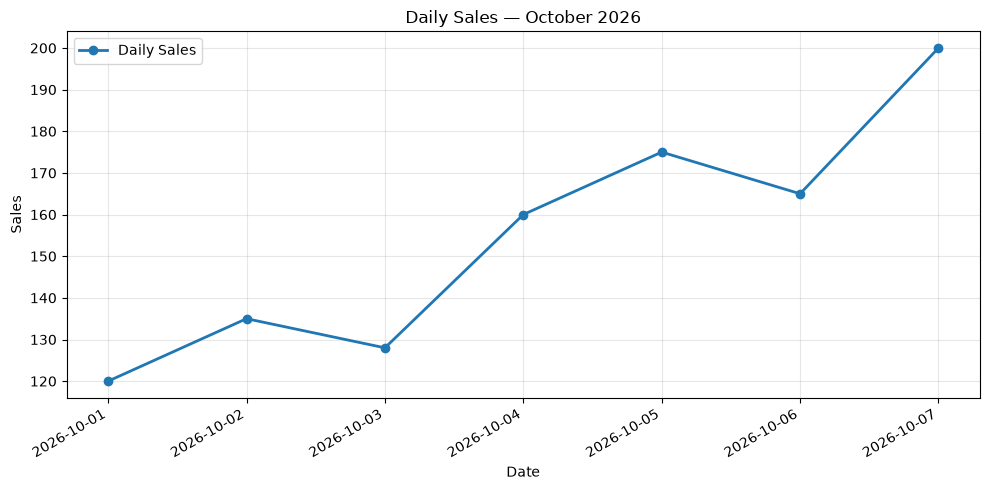

In [ ]:
# Step 2 — Time Series Line Chart બનાવો
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df["Date"],
    df["Sales"],
    marker="o",
    linewidth=2,
    label="Daily Sales"
)

ax.set_title("Daily Sales — October 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Sales")
ax.legend()
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

# fig.autofmt_xdate() તારીખના labels વાંચવામાં સરળ બનાવવા માટે તેમને યોગ્ય રીતે ફેરવવામાં મદદ કરે છે.


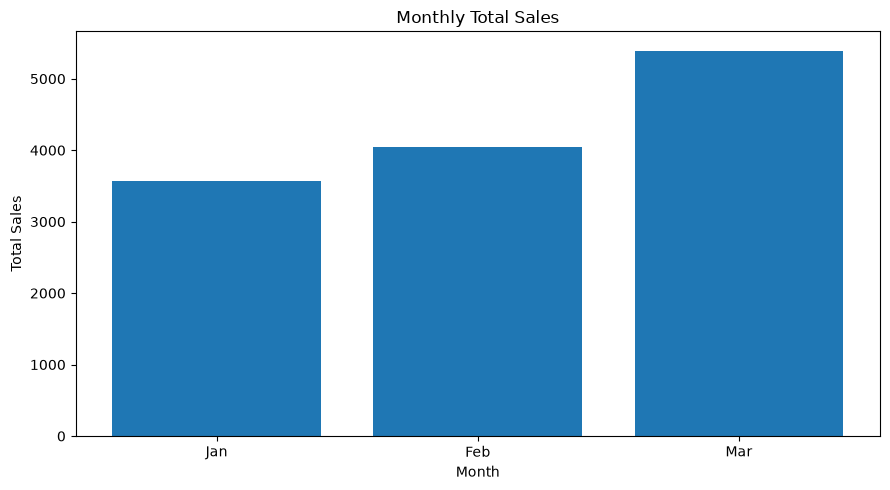

In [ ]:
# 6. Daily Data માંથી Monthly Sales કાઢવી
# Time Series માં resampling વડે daily data ને monthly અથવા weekly data માં ફેરવી શકાય છે.

import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Date": pd.date_range("2026-01-01", periods=90, freq="D"),
    "Sales": range(100, 190)
})

df = df.set_index("Date") # date frame index set

monthly_sales = df["Sales"].resample("MS").sum() # total month 
 
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    monthly_sales.index.strftime("%b"), #jan,feb,mar sort name aapse
    monthly_sales.values
)

ax.set_title("Monthly Total Sales")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [12]:
# 7. કયો Advanced Chart ક્યારે વાપરવો?
# Chart	યોગ્ય ઉપયોગ	Example
# Stacked Bar	કુલ અને category contribution	મહિના પ્રમાણે product sales
# Stacked Area	સમય સાથે categories નો cumulative trend	Revenue contribution over time
# Error Bar	Measurement variability અથવા uncertainty	Average marks સાથે confidence range
# Time Series	તારીખ પ્રમાણે trend	Daily sales અથવા monthly revenue

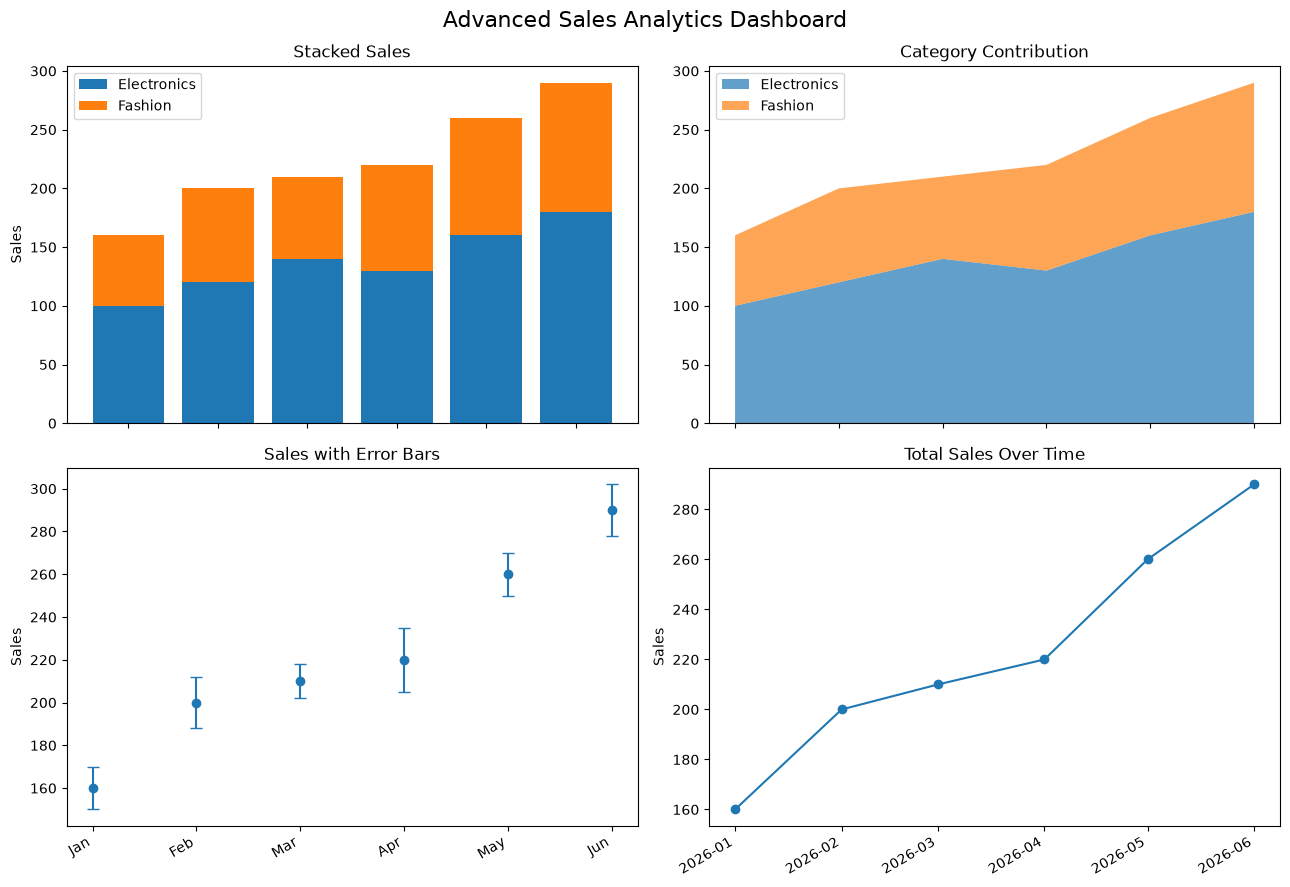

In [13]:
# 8. Mini Practical — ચાર Advanced Charts એક જ Figure માં
# આ practical માં Stacked Bar, Area, Error Bar અને Time Series ને એક જ dashboard માં જોડીએ

import matplotlib.pyplot as plt
import pandas as pd

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
electronics = [100, 120, 140, 130, 160, 180]
fashion = [60, 80, 70, 90, 100, 110]

dates = pd.date_range("2026-01-01", periods=6, freq="MS")
total_sales = [
    e + f for e, f in zip(electronics, fashion)
]

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. Stacked Bar
ax[0, 0].bar(months, electronics, label="Electronics")
ax[0, 0].bar(
    months, fashion,
    bottom=electronics,
    label="Fashion"
)
ax[0, 0].set_title("Stacked Sales")
ax[0, 0].set_ylabel("Sales")
ax[0, 0].legend()

# 2. Area Chart
ax[0, 1].stackplot(
    months,
    electronics,
    fashion,
    labels=["Electronics", "Fashion"],
    alpha=0.7
)
ax[0, 1].set_title("Category Contribution")
ax[0, 1].legend()

# 3. Error Bars
ax[1, 0].errorbar(
    months,
    total_sales,
    yerr=[10, 12, 8, 15, 10, 12],
    fmt="o",
    capsize=4
)
ax[1, 0].set_title("Sales with Error Bars")
ax[1, 0].set_ylabel("Sales")

# 4. Time Series
ax[1, 1].plot(dates, total_sales, marker="o")
ax[1, 1].set_title("Total Sales Over Time")
ax[1, 1].set_ylabel("Sales")

fig.suptitle("Advanced Sales Analytics Dashboard", fontsize=16)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

In [ ]:
# 10. Practical Assignment Checklist
# Assignment Progress
# 0/6 પૂર્ણ

# [ ] Electronics અને Fashion માટે Stacked Bar Chart બનાવો.
# [ ] ત્રણ categories નો Stacked Area Chart બનાવો.
# [ ] Average values માટે Error Bars ઉમેરો.
# [ ] CSV માંથી Date અને Sales વાંચીને Time Series બનાવો.
# [ ] Daily Sales ને Monthly Total માં resample કરો.
# [ ] ચાર Advanced Charts સાથે dashboard તૈયાર કરો.